## v2.1 Particles below the sea bed (from v2.Meso_boundaries_trial, seed 16)

1. find the particles that are below the W bottom **of the cell parcels uses** (T cell (j,i) has corners f(j-1,i-1)..f(j,i))
2. replay each one at dt resolution (20 min) from the last 6-hourly output before it crossed, sampling UVW
3. plot plan view (cells coloured wet/dry at the particle depth) and depth vs time with the W bottom

In [1]:
run_time_days = 100
out_put_step_hours = 6
time_step_minutes = 20
rdm_seed = 16
start_date = "1994-07-05"

Hgr = "/work/bk1450/b383184/Amazon/Mercator/data/Hgr_cmesh.nc"
Zgr = "/work/bk1450/b383184/Amazon/Mercator/data/Zgr_cmesh2.nc"
pathUVW = '/work/bk1450/b383184/Amazon/Mercator/data/variables_c/UVW'
tracks = f'tracks_boundaries_{rdm_seed}/Parcels_boundaries_{rdm_seed}_{start_date}.zarr'
replay_path = f'tracks_boundaries_{rdm_seed}/replay/'

In [2]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from datetime import timedelta
from parcels import FieldSet, ParticleSet, JITParticle, Variable, AdvectionRK4_3D

groups = ["coast", "shelf_bottom", "ocean_bottom"]

_h = xr.open_dataset(Hgr); _z = xr.open_dataset(Zgr)
glamf = _h.glamf.isel(t=0).values
gphif = _h.gphif.isel(t=0).values
mbathy = _z.mbathy.isel(t=0).values.astype(int)
depthw = _z.gdepw_0.isel(t=0).values
nz = len(depthw)
w_bottom = np.where(mbathy > 0, depthw[np.minimum(mbathy, nz - 1)], 0.0)

def tcell(lon, lat):
    """T cell (j,i) parcels uses: corners f(j-1,i-1)..f(j,i)"""
    i = np.searchsorted(glamf[250, :], lon)
    j = np.searchsorted(gphif[:, 600], lat)
    for _ in range(2):   # refine on the (nearly regular) curvilinear grid
        i = np.clip(i, 1, glamf.shape[1] - 1); j = np.clip(j, 1, glamf.shape[0] - 1)
        i = i + (lon > glamf[j, i]).astype(int) - (lon <= glamf[j, i - 1]).astype(int)
        j = j + (lat > gphif[j, i]).astype(int) - (lat <= gphif[j - 1, i]).astype(int)
    return j, i

## 1. Which particles are below the W bottom

In [3]:
ds = xr.open_zarr(tracks).compute()
lon, lat, z, tim = ds.lon.values, ds.lat.values, ds.z.values, ds.time.values
grp = ds.group.values.astype(int)

J, I = tcell(np.nan_to_num(lon), np.nan_to_num(lat))
below = (z > w_bottom[J, I]) & ~np.isnan(z)
ids = np.where(below.any(axis=1))[0]

rows = []
for p in ids:
    t = np.argmax(below[p])
    ja, ia, jb, ib = J[p, t-1], I[p, t-1], J[p, t], I[p, t]
    rows.append(dict(traj=p, group=groups[grp[p]], day=t*out_put_step_hours/24,
                     z_before=z[p, t-1], cell_before=(ja, ia), mbathy_before=mbathy[ja, ia], Wbottom_before=w_bottom[ja, ia],
                     z_after=z[p, t], cell_after=(jb, ib), mbathy_after=mbathy[jb, ib], Wbottom_after=w_bottom[jb, ib],
                     move=('diagonal' if (jb != ja and ib != ia) else 'side'),
                     days_below=below[p].sum()*out_put_step_hours/24, z_end=z[p, -1]))
table = pd.DataFrame(rows).set_index('traj').round(2)
table

,group,day,z_before,cell_before,mbathy_before,Wbottom_before,z_after,cell_after,mbathy_after,Wbottom_after,move,days_below,z_end
traj,,,,,,,,,,,,,
655,coast,16.25,7.07,"(125, 538)",9,12.40,7.17,"(126, 538)",6,7.17,side,83.75,7.17
1358,shelf_bottom,13.50,32.09,"(126, 585)",17,43.70,32.95,"(127, 584)",12,19.99,diagonal,86.50,32.95
1398,shelf_bottom,6.00,43.38,"(116, 600)",17,43.70,43.39,"(117, 599)",14,27.24,diagonal,94.00,43.39
1608,shelf_bottom,26.25,8.78,"(150, 549)",17,43.70,8.19,"(151, 548)",6,7.17,diagonal,73.75,8.19
1705,shelf_bottom,7.75,31.44,"(114, 596)",15,31.84,31.87,"(115, 595)",15,31.84,diagonal,92.25,31.87
1975,shelf_bottom,18.00,23.18,"(121, 571)",14,27.24,23.33,"(122, 570)",12,19.99,diagonal,82.00,23.33
2154,ocean_bottom,53.00,4622.21,"(225, 591)",48,5052.47,4624.36,"(226, 590)",47,4617.46,diagonal,47.00,4624.36
2446,ocean_bottom,66.50,3788.42,"(218, 637)",46,4196.82,3792.56,"(218, 638)",45,3792.47,side,33.50,3792.56
2726,ocean_bottom,77.25,4623.30,"(247, 593)",48,5052.47,4637.42,"(248, 594)",47,4617.46,diagonal,22.75,4637.42


## 2. Replay each crossing at dt resolution

In [4]:
months = pd.period_range(pd.Timestamp(start_date) - pd.DateOffset(months=1),
                         pd.Timestamp(start_date) + pd.DateOffset(days=run_time_days + 31), freq='M')
files = lambda v, s: [f"{pathUVW}/{v}_{m.year}-{m.month:02d}{s}" for m in months]
ufiles, vfiles, wfiles = files('U', 'c.nc'), files('V', 'c.nc'), files('W', 'fc.nc')

filenames = {v: {"data": f, "lon": Hgr, "lat": Hgr, "depth": wfiles[0]} for v, f in zip("UVW", (ufiles, vfiles, wfiles))}
dims = {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"}
fieldset = FieldSet.from_nemo(filenames, {"U": "vozocrtx", "V": "vomecrty", "W": "vovecrtz"},
                              {v: dims for v in "UVW"}, deferred_load=True, allow_time_extrapolation=False)

SampleParticle = JITParticle.add_variables([Variable('u', dtype=np.float32, initial=0),
                                            Variable('v', dtype=np.float32, initial=0),
                                            Variable('w', dtype=np.float32, initial=0)])

def SampleUVW(particle, fieldset, time):
    (uu, vv, ww) = fieldset.UVW[time, particle.depth, particle.lat, particle.lon, particle]
    particle.u = uu
    particle.v = vv
    particle.w = ww

In [5]:
replay = {}
for p in ids:
    t0 = np.argmax(below[p]) - 1
    pset = ParticleSet(fieldset, pclass=SampleParticle, lon=[lon[p, t0]], lat=[lat[p, t0]], depth=[z[p, t0]], time=[tim[p, t0]])
    out = replay_path + f'replay_{p}.zarr'
    pset.execute([SampleUVW, AdvectionRK4_3D], runtime=timedelta(hours=out_put_step_hours + 6),
                 dt=timedelta(minutes=time_step_minutes), verbose_progress=False,
                 output_file=pset.ParticleFile(name=out, outputdt=timedelta(minutes=time_step_minutes), chunks=(1, 100)))
    r = xr.open_zarr(out).isel(trajectory=0).compute()
    r = r.where(r.lat.notnull(), drop=True)
    j, i = tcell(r.lon.values, r.lat.values)
    r['j'], r['i'] = ('obs', j), ('obs', i)
    r['mbathy'] = ('obs', mbathy[j, i])
    r['Wbottom'] = ('obs', w_bottom[j, i])
    r['below'] = r.z > r.Wbottom
    replay[p] = r

# the step that crosses, and the last velocities before it
rows = []
for p, r in replay.items():
    k = int(np.argmax(r.below.values))
    rows.append(dict(traj=p, reproduced=bool(np.isclose(r.z.values[-1], z[p, np.argmax(below[p])], atol=0.01)),
                     minutes_after_output=k*time_step_minutes,
                     z_last_wet=r.z.values[k-1], z_below=r.z.values[k],
                     last_u_m_s=r.u.values[k-1]*1852*60*np.cos(np.deg2rad(r.lat.values[k-1])),
                     last_v_m_s=r.v.values[k-1]*1852*60, last_w_m_s=r.w.values[k-1],
                     step_h_m=1852*60*np.hypot((r.lon.values[k]-r.lon.values[k-1])*np.cos(np.deg2rad(r.lat.values[k])), r.lat.values[k]-r.lat.values[k-1]),
                     step_z_m=r.z.values[k]-r.z.values[k-1],
                     uvw_after=(float(r.u.values[k]), float(r.v.values[k]), float(r.w.values[k]))))
crossing = pd.DataFrame(rows).set_index('traj')
crossing.style.format({c: '{:.2e}' for c in ['last_u_m_s', 'last_v_m_s', 'last_w_m_s']})

INFO: Output files are stored in tracks_boundaries_16/replay/replay_655.zarr.


INFO: Output files are stored in tracks_boundaries_16/replay/replay_1358.zarr.


INFO: Output files are stored in tracks_boundaries_16/replay/replay_1398.zarr.


INFO: Output files are stored in tracks_boundaries_16/replay/replay_1608.zarr.


INFO: Output files are stored in tracks_boundaries_16/replay/replay_1705.zarr.


INFO: Output files are stored in tracks_boundaries_16/replay/replay_1975.zarr.


INFO: Output files are stored in tracks_boundaries_16/replay/replay_2154.zarr.


INFO: Output files are stored in tracks_boundaries_16/replay/replay_2446.zarr.


INFO: Output files are stored in tracks_boundaries_16/replay/replay_2726.zarr.


,reproduced,minutes_after_output,z_last_wet,z_below,last_u_m_s,last_v_m_s,last_w_m_s,step_h_m,step_z_m,uvw_after
traj,,,,,,,,,,
655,True,140,7.161613,7.169515,2.11e-02,1.25e-02,1.32e-05,14.694069,0.007902,"(0.0, 0.0, 0.0)"
1358,True,300,32.906481,32.954250,-2.50e-01,8.39e-02,4.78e-05,263.909778,0.047769,"(0.0, 0.0, 0.0)"
1398,True,20,43.377198,43.385208,-2.50e-01,1.36e-01,1.33e-05,170.507779,0.008010,"(0.0, 0.0, 0.0)"
1608,True,200,8.222235,8.191169,-2.04e-01,4.46e-01,-5.18e-05,294.104502,-0.031065,"(0.0, 0.0, 0.0)"
1705,True,320,31.807835,31.865463,-3.48e-01,1.75e-01,9.60e-05,233.445343,0.057628,"(0.0, 0.0, 0.0)"
1975,True,140,23.308836,23.326002,-1.73e-01,1.06e-01,1.72e-05,202.863099,0.017166,"(0.0, 0.0, 0.0)"
2154,True,240,4624.272789,4624.362906,-1.38e-01,1.81e-01,1.51e-04,136.358032,0.090117,"(0.0, 0.0, 0.0)"
2446,True,80,3791.650363,3792.557340,2.84e-02,1.23e-01,9.05e-04,126.166212,0.906976,"(0.0, 0.0, 0.0)"
2726,True,280,4636.897672,4637.421939,1.90e-01,1.55e-01,8.73e-04,146.948068,0.524267,"(0.0, 0.0, 0.0)"


## 3. Plots

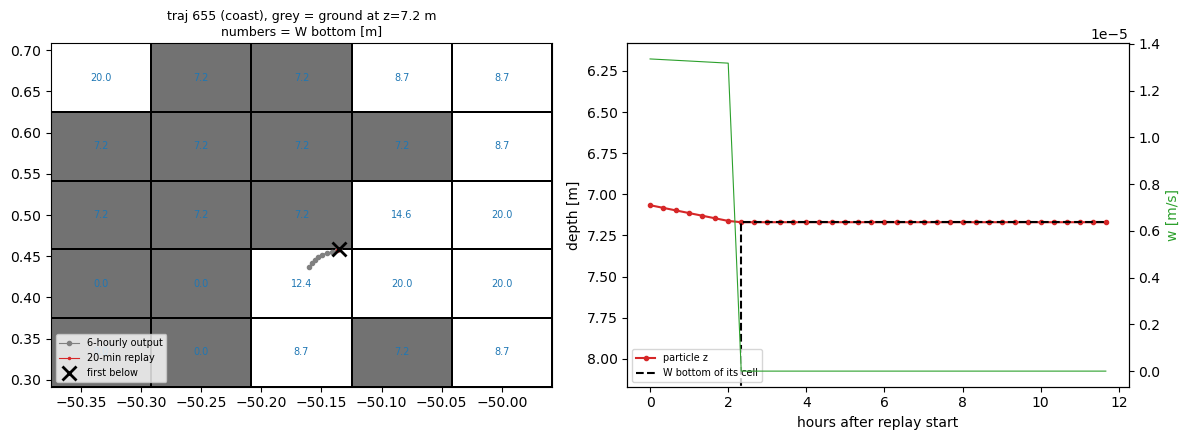

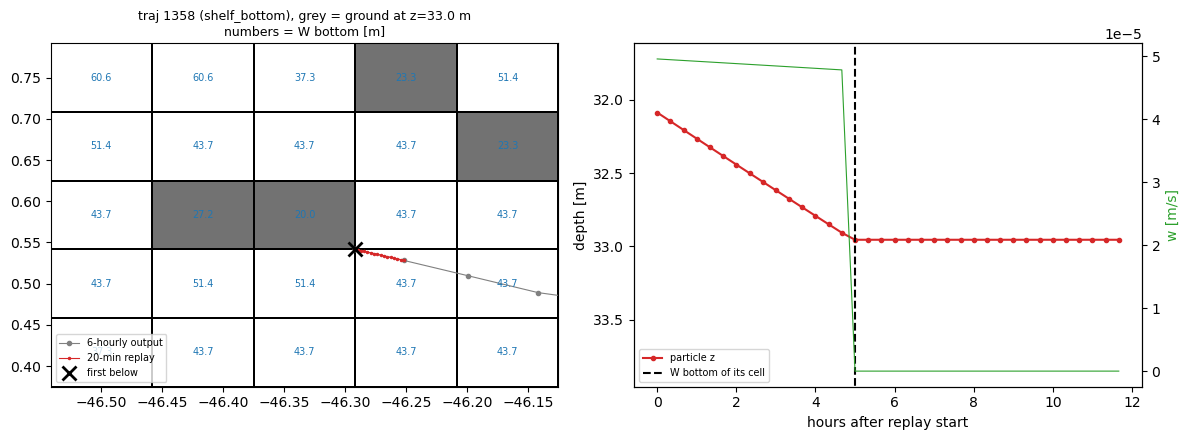

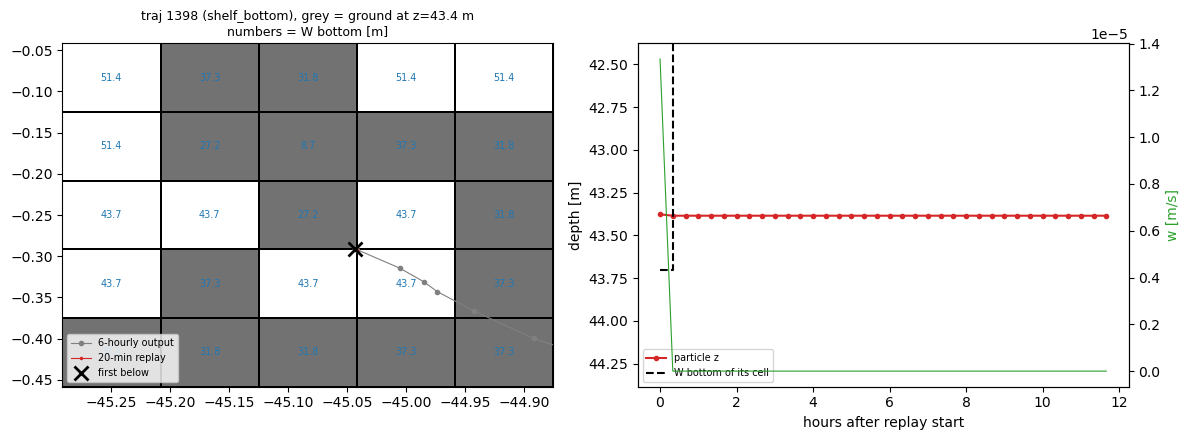

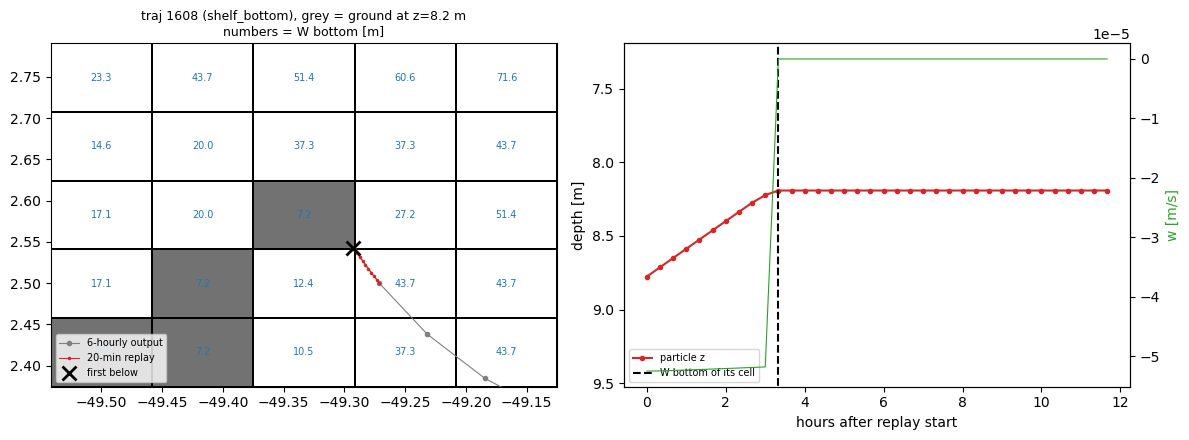

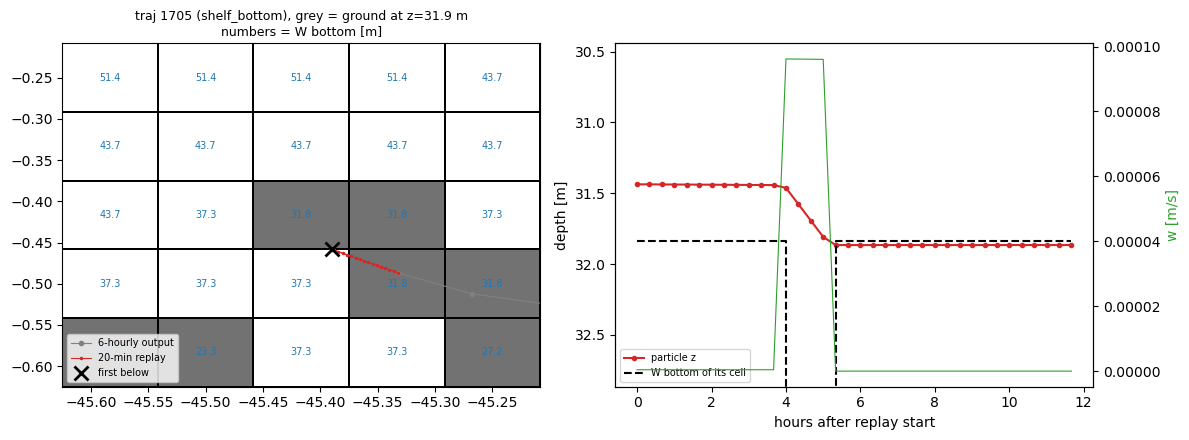

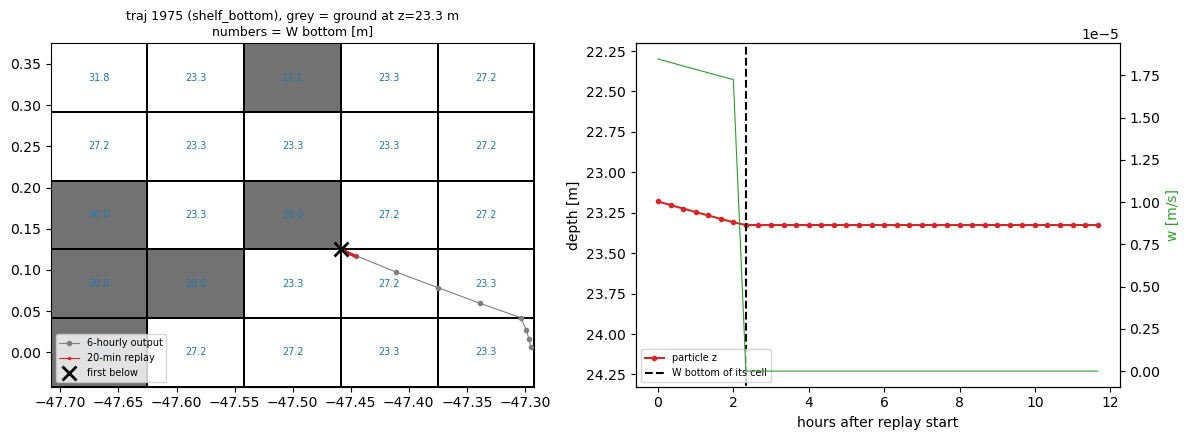

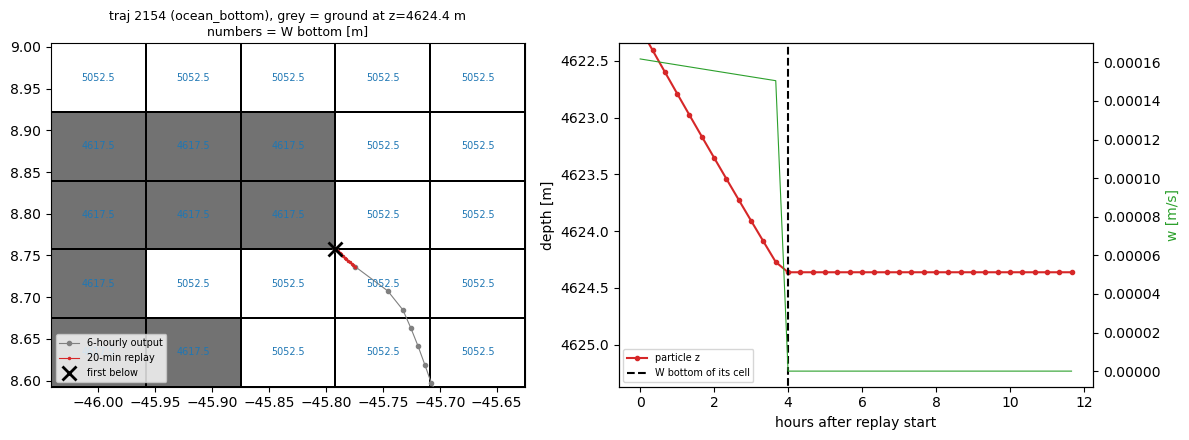

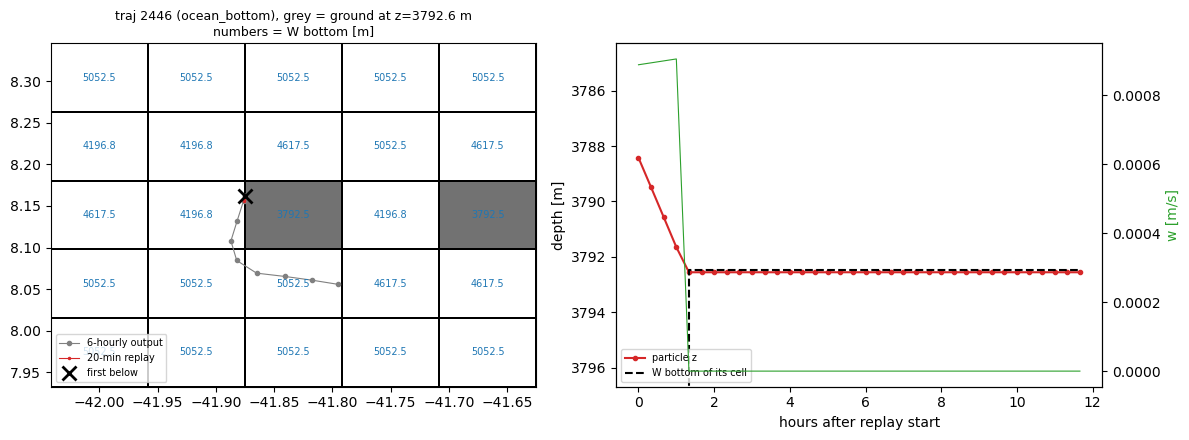

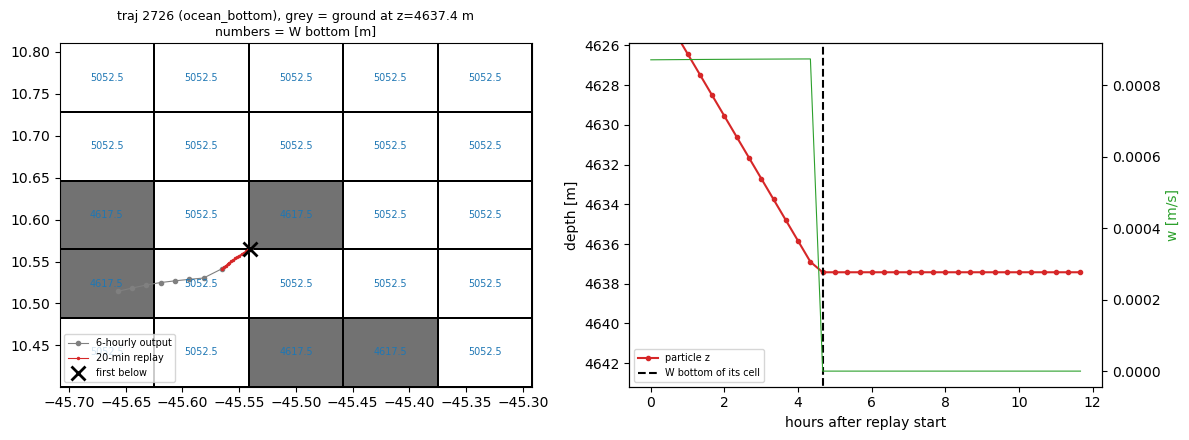

In [6]:
def plan_view(ax, p, r, n=2):
    k = int(np.argmax(r.below.values))
    jc, ic = int(r.j.values[k]), int(r.i.values[k])
    kz = np.searchsorted(depthw, r.z.values[k]) - 1            # level of the particle
    js, is_ = slice(jc-n, jc+n+1), slice(ic-n, ic+n+1)
    X = glamf[jc-n-1:jc+n+1, ic-n-1:ic+n+1]; Y = gphif[jc-n-1:jc+n+1, ic-n-1:ic+n+1]
    dry = (mbathy[js, is_] <= kz).astype(float)                   # land at the particle's level
    ax.pcolormesh(X, Y, dry, cmap='Greys', vmin=0, vmax=1.6, edgecolors='k', linewidth=0.3)
    for jj in range(jc-n, jc+n+1):
        for ii in range(ic-n, ic+n+1):
            ax.text(0.25*(glamf[jj-1, ii-1]+glamf[jj, ii]+glamf[jj-1, ii]+glamf[jj, ii-1]),
                    0.25*(gphif[jj-1, ii-1]+gphif[jj, ii]+gphif[jj-1, ii]+gphif[jj, ii-1]),
                    f"{w_bottom[jj, ii]:.1f}", ha='center', va='center', fontsize=7, color='tab:blue')
    t = np.argmax(below[p])
    sl = slice(max(t-8, 0), min(t+2, lon.shape[1]))
    ax.plot(lon[p, sl], lat[p, sl], 'o-', color='0.5', ms=3, lw=0.8, label='6-hourly output')
    ax.plot(r.lon, r.lat, '.-', color='tab:red', ms=3, lw=0.8, label='20-min replay')
    ax.plot(r.lon.values[k], r.lat.values[k], 'x', color='k', ms=10, mew=2, label='first below')
    ax.set_xlim(X.min(), X.max()); ax.set_ylim(Y.min(), Y.max())
    ax.set_title(f"traj {p} ({groups[grp[p]]}), grey = ground at z={r.z.values[k]:.1f} m\nnumbers = W bottom [m]", fontsize=9)

def depth_view(ax, p, r):
    tr = (r.time.values - r.time.values[0]) / np.timedelta64(1, 'h')
    ax.plot(tr, r.z, '.-', color='tab:red', label='particle z')
    ax.step(tr, r.Wbottom, where='post', color='k', ls='--', label='W bottom of its cell')
    k = int(np.argmax(r.below.values))
    zmin, zmax = r.z.values[max(k-6, 0):k+3].min(), r.z.values[max(k-6, 0):k+3].max()
    pad = max(zmax - zmin, 1)
    ax.set_ylim(zmax + pad, zmin - pad)
    ax2 = ax.twinx(); ax2.plot(tr, r.w, color='tab:green', lw=0.8); ax2.set_ylabel('w [m/s]', color='tab:green')
    ax.set_xlabel('hours after replay start'); ax.set_ylabel('depth [m]')
    ax.legend(fontsize=7, loc='lower left')

for p, r in replay.items():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    plan_view(axes[0], p, r)
    depth_view(axes[1], p, r)
    axes[0].legend(fontsize=7, loc='lower left')
    plt.tight_layout()
    plt.show()

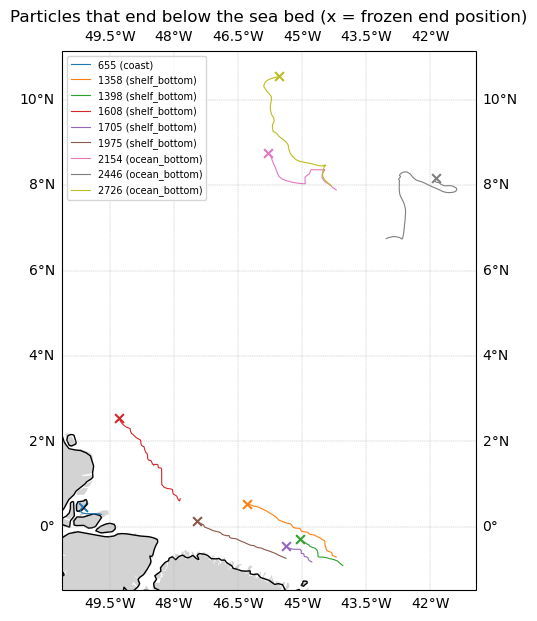

In [7]:
# whole trajectories of these particles, with their frozen end point
import cartopy.crs as ccrs
import cartopy.feature as cfeature
fig = plt.figure(figsize=(9, 7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='lightgray'); ax.coastlines(resolution='50m')
ax.gridlines(draw_labels=True, linestyle='--', linewidth=0.3)
for p in ids:
    l, = ax.plot(lon[p], lat[p], lw=0.8, transform=ccrs.PlateCarree(), label=f"{p} ({groups[grp[p]]})")
    ax.scatter(lon[p, -1], lat[p, -1], marker='x', s=40, color=l.get_color(), transform=ccrs.PlateCarree())
ax.legend(fontsize=7)
plt.title('Particles that end below the sea bed (x = frozen end position)')
plt.show()